# 📊 General Text EDA: Vocabulary & OOV Overlap Analysis
### Universal Diagnostic for All Text Competitions (NLU & NLG)
Tujuan: Menghitung persentase kata pada Test Set yang tidak pernah terlihat di Train Set (Out-Of-Vocabulary / OOV Rate).


In [1]:
# 1. Master Config
TRAIN_PATH = "demo_data/train.csv"
TEST_PATH = "demo_data/test.csv"
TEXT_COL = "full_text"


In [2]:
# 2. Imports
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [3]:
# 3. Load Datasets
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

def extract_vocab(series):
    tokens = set()
    for text in series.dropna():
        words = re.findall(r'\b\w+\b', str(text).lower())
        tokens.update(words)
    return tokens

train_vocab = extract_vocab(train_df[TEXT_COL])
test_vocab = extract_vocab(test_df[TEXT_COL])

common_vocab = train_vocab.intersection(test_vocab)
oov_vocab = test_vocab.difference(train_vocab)

oov_rate = len(oov_vocab) / max(1, len(test_vocab)) * 100

print("=== VOCABULARY OVERLAP AUDIT ===")
print(f"Train Vocab Size:   {len(train_vocab):,}")
print(f"Test Vocab Size:    {len(test_vocab):,}")
print(f"Shared Vocab Size:  {len(common_vocab):,}")
print(f"OOV Word Count:     {len(oov_vocab):,}")
print(f"OOV Rate:           {oov_rate:.2f}%")


=== VOCABULARY OVERLAP AUDIT ===
Train Vocab Size:   128
Test Vocab Size:    46
Shared Vocab Size:  13
OOV Word Count:     33
OOV Rate:           71.74%


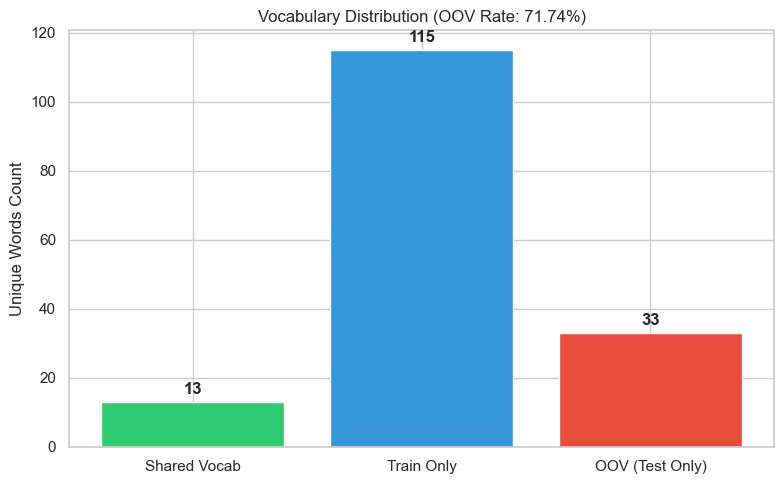

Sample OOV words in Test: ['menjadi', 'planning', 'challenges', 'kolaborasi', 'execution', 'continue', 'keberhasilan', 'strategic', 'modern', 'technological', 'implementasi', 'literasi', 'necessitates', '4', 'workforce']


In [4]:
# 4. Overlap Visualization
labels = ['Shared Vocab', 'Train Only', 'OOV (Test Only)']
sizes = [len(common_vocab), len(train_vocab - test_vocab), len(oov_vocab)]
colors = ['#2ecc71', '#3498db', '#e74c3c']

plt.figure(figsize=(8, 5))
plt.bar(labels, sizes, color=colors)
plt.title(f"Vocabulary Distribution (OOV Rate: {oov_rate:.2f}%)")
plt.ylabel("Unique Words Count")
for idx, val in enumerate(sizes):
    plt.text(idx, val + max(sizes)*0.02, f"{val:,}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print("Sample OOV words in Test:", list(oov_vocab)[:15])


### 📋 Master Decision Matrix (OOV Rate):
1. **Jika OOV Rate $< 10\%$:** Model berbasis kata (TF-IDF + GBDT / n-gram linear) akan berkinerja sangat kuat dan stabil.
2. **Jika OOV Rate $> 20\%$:** Model TF-IDF murni **pasti mengalami degradasi skor di Private LB**. Wajib memprioritaskan Subword Pretrained Transformer (BPE / WordPiece seperti DeBERTa, RoBERTa, atau IndoBERT) yang mampu memecah kata baru menjadi morfem subkata.
